In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("titanic.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex          

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[features].copy()
y = df["Survived"].to_numpy(dtype=float)


X["FamilySize"] = X["SibSp"] + X["Parch"] + 1

print("Features selected:", X.columns.tolist())
print("Target shape:", y.shape)

Features selected: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize']
Target shape: (891,)


In [9]:
indices = np.arange(len(X))
np.random.shuffle(indices)

split_index = int(0.8 * len(indices))

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [10]:

for col in ["Age", "Fare"]:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

for col in ["Embarked"]:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)


X_train = pd.get_dummies(
    X_train, columns=["Sex", "Embarked"], dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=["Sex", "Embarked"], dtype=int
)


X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


means = X_train.mean()
stds = X_train.std().replace(0, 1)

X_train = ((X_train - means) / stds).to_numpy(dtype=float)
X_test = ((X_test - means) / stds).to_numpy(dtype=float)

print("Preprocessing completed!")
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Preprocessing completed!
Training feature shape: (712, 11)
Testing feature shape: (179, 11)


In [ ]:
class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=2000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            linear_output = np.dot(X, self.weights) + self.bias
            probabilities = self.sigmoid(linear_output)

          
            epsilon = 1e-15
            probabilities = np.clip(
                probabilities, epsilon, 1 - epsilon
            )

            loss = -np.mean(
                y * np.log(probabilities)
                + (1 - y) * np.log(1 - probabilities)
            )

            self.loss_history.append(loss)

       
            dw = np.dot(X.T, probabilities - y) / n_samples
            db = np.mean(probabilities - y)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.sigmoid(linear_output)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)

In [13]:
model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=2000
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Model training completed!")
print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test[:10].astype(int))

Model training completed!
First 10 predictions: [0 0 0 1 1 0 1 0 0 0]
First 10 actual values: [0 0 1 1 1 0 1 1 0 0]


In [14]:
y_test_int = y_test.astype(int)

TP = np.sum((y_test_int == 1) & (y_pred == 1))
TN = np.sum((y_test_int == 0) & (y_pred == 0))
FP = np.sum((y_test_int == 0) & (y_pred == 1))
FN = np.sum((y_test_int == 1) & (y_pred == 0))

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0
specificity = TN / (TN + FP) if TN + FP else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"F1-score:    {f1_score:.4f}")
print(f"Specificity: {specificity:.4f}")

print("\nConfusion matrix counts:")
print("True Positives:", TP)
print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)

Accuracy:    0.7989
Precision:   0.7231
Recall:      0.7231
F1-score:    0.7231
Specificity: 0.8421

Confusion matrix counts:
True Positives: 47
True Negatives: 96
False Positives: 18
False Negatives: 18


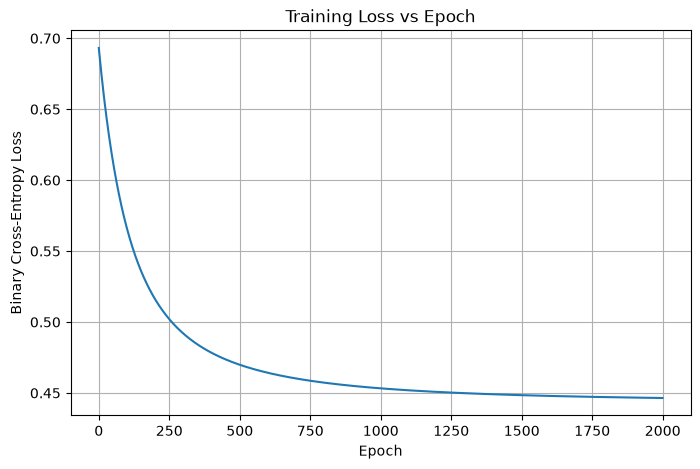

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(model.loss_history)
plt.title("Training Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()

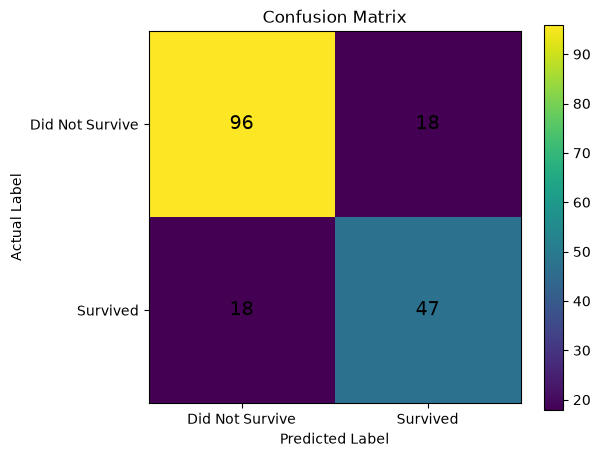

In [16]:
confusion_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])
plt.yticks([0, 1], ["Did Not Survive", "Survived"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, confusion_matrix[i, j],
            ha="center", va="center", fontsize=14
        )

plt.colorbar()
plt.show()

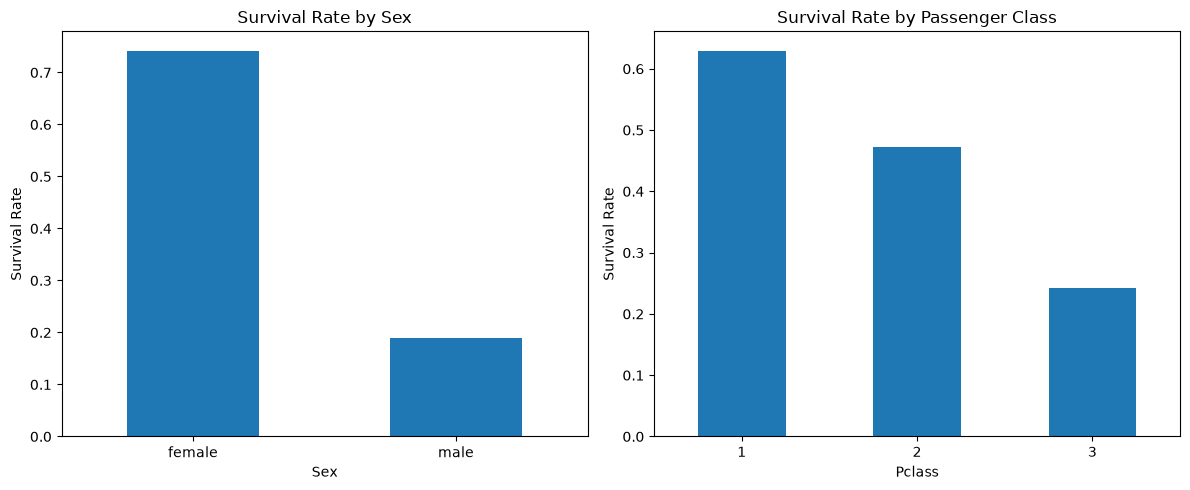

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.groupby("Sex")["Survived"].mean().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("Pclass")["Survived"].mean().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_ylabel("Survival Rate")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [18]:
with open("metrics.txt", "w") as file:
    file.write("Titanic Logistic Regression Results\n")
    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"Precision: {precision:.4f}\n")
    file.write(f"Recall: {recall:.4f}\n")
    file.write(f"F1-score: {f1_score:.4f}\n")
    file.write(f"Specificity: {specificity:.4f}\n")

print("Metrics saved successfully to metrics.txt")

Metrics saved successfully to metrics.txt
